# Lab assignment №1, part 2

This lab assignment consists of several parts. You are supposed to make some transformations, train some models, estimate the quality of the models and explain your results.

Several comments:
* Don't hesitate to ask questions, it's a good practice.
* No private/public sharing, please. The copied assignments will be graded with 0 points.
* Blocks of this lab will be graded separately.

__*This is the second part of the assignment. First and third parts are waiting for you in the same directory.*__

## Part 2. Data preprocessing, model training and evaluation.

### 1. Reading the data
Today we work with the [dataset](https://archive.ics.uci.edu/ml/datasets/Statlog+%28Vehicle+Silhouettes%29), describing different cars for multiclass ($k=4$) classification problem. The data is available below.

In [1]:
# If on colab, uncomment the following lines

! wget https://raw.githubusercontent.com/girafe-ai/ml-course/22f_made/homeworks/lab01_ml_pipeline/car_data.csv

--2026-11-15 16:26:01--  https://raw.githubusercontent.com/girafe-ai/ml-course/22f_made/homeworks/lab01_ml_pipeline/car_data.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.108.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 58374 (57K) [text/plain]
Saving to: ‘car_data.csv’

car_data.csv        100%[===================>]  57.01K  --.-KB/s    in 0.04s   

2026-11-15 16:26:01 (1.58 MB/s) - ‘car_data.csv’ saved [58374/58374]



In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

dataset = pd.read_csv('car_data.csv', delimiter=',', header=None).values
data = dataset[:, :-1].astype(int)
target = dataset[:, -1]

print(data.shape, target.shape)

X_train, X_test, y_train, y_test = train_test_split(data, target, test_size=0.35)
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(846, 19) (846,)
(549, 19) (549,) (297, 19) (297,)


To get some insights about the dataset, `pandas` might be used. The `train` part is transformed to `pd.DataFrame` below.

In [3]:
X_train_pd = pd.DataFrame(X_train)

# First 15 rows of our dataset.
X_train_pd.head(15)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
0,748,93,46,85,169,66,9,151,44,19,147,169,339,179,67,0,4,195,204
1,780,109,47,96,206,64,9,198,33,23,150,219,586,191,70,4,13,190,198
2,792,100,51,104,163,52,10,206,32,23,164,217,631,193,69,5,21,188,196
3,596,90,40,83,178,61,8,178,37,21,132,199,472,157,71,1,14,187,193
4,323,98,51,96,203,66,10,188,35,22,157,207,533,231,68,10,1,191,199
5,418,87,43,70,169,72,7,152,44,19,145,177,341,171,76,6,12,184,187
6,287,88,43,84,136,55,11,154,44,19,150,174,350,164,73,6,2,185,196
7,154,89,40,79,154,64,9,144,46,19,139,168,311,149,71,8,7,188,197
8,359,100,49,96,206,63,9,186,35,22,156,202,519,176,62,3,5,197,205
9,789,90,39,85,160,59,7,163,41,20,131,189,396,158,71,7,13,186,192


Methods `describe` and `info` deliver some useful information.

In [4]:
X_train_pd.describe()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
count,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000
mean,417.136612,93.679417,44.770492,82.267760,170.296903,62.109290,8.732240,168.856102,40.865209,20.575592,147.710383,189.216758,439.677596,173.983607,72.595628,6.220401,12.675774,189.112933,195.821494
std,249.574597,8.303282,6.098205,15.614753,34.835657,8.899422,5.450782,32.734935,7.697287,2.555984,14.348946,31.677584,174.522027,32.149311,8.192509,4.920227,9.110062,6.210569,7.541915
min,0.000000,73.000000,33.000000,40.000000,105.000000,47.000000,2.000000,112.000000,26.000000,17.000000,118.000000,130.000000,184.000000,109.000000,59.000000,0.000000,0.000000,176.000000,181.000000
25%,190.000000,87.000000,40.000000,70.000000,142.000000,57.000000,7.000000,147.000000,34.000000,19.000000,138.000000,168.000000,321.000000,148.000000,67.000000,2.000000,6.000000,185.000000,191.000000
50%,413.000000,93.000000,44.000000,80.000000,169.000000,61.000000,8.000000,157.000000,43.000000,20.000000,146.000000,179.000000,365.000000,173.000000,71.000000,5.000000,11.000000,189.000000,197.000000
75%,638.000000,100.000000,49.000000,96.000000,197.000000,66.000000,10.000000,195.000000,46.000000,22.000000,159.000000,216.000000,573.000000,197.000000,75.000000,9.000000,19.000000,193.000000,201.000000
max,845.000000,119.000000,59.000000,110.000000,333.000000,138.000000,55.000000,265.000000,61.000000,29.000000,188.000000,320.000000,1018.000000,264.000000,135.000000,22.000000,41.000000,206.000000,211.000000


In [5]:
X_train_pd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 549 entries, 0 to 548
Data columns (total 19 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   0       549 non-null    int64
 1   1       549 non-null    int64
 2   2       549 non-null    int64
 3   3       549 non-null    int64
 4   4       549 non-null    int64
 5   5       549 non-null    int64
 6   6       549 non-null    int64
 7   7       549 non-null    int64
 8   8       549 non-null    int64
 9   9       549 non-null    int64
 10  10      549 non-null    int64
 11  11      549 non-null    int64
 12  12      549 non-null    int64
 13  13      549 non-null    int64
 14  14      549 non-null    int64
 15  15      549 non-null    int64
 16  16      549 non-null    int64
 17  17      549 non-null    int64
 18  18      549 non-null    int64
dtypes: int64(19)
memory usage: 81.6 KB


### 2. Machine Learning pipeline
Here you are supposed to perform the desired transformations. Please, explain your results briefly after each task.

#### 2.0. Data preprocessing
* Make some transformations of the dataset (if necessary). Briefly explain the transformations

In [6]:
# хочу посмотреть на 1 столбец
np.sort(X_train_pd[0].values)[:20]

array([ 0,  2,  4,  5,  6,  8,  9, 10, 11, 13, 14, 17, 18, 20, 23, 24, 25,
       26, 27, 28])

По описательным статистикам первого столбца можно предположить, что он содержит ИД объекта (или какой-то признак, уникальный для каждого объекта), поскольку все его значения уникальны. Он не несёт информацию о характеристиках автомобиля, поэтому исключаем его из признаков

Остальные признаки имеют разные масштабы, из-за чего признаки с большими значениями могут сильнее влиять на результат. Необходимо масштабирование, но перед этим посмотрим на выбросы:

In [7]:
X_train_new = X_train[:, 1:]
X_test_new = X_test[:, 1:]

In [8]:
# посмотрим на выбросы
df = pd.DataFrame(X_train_new)
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3 - Q1

outliers = (df < Q1 - 1.5 * IQR) | (df > Q3 + 1.5 * IQR)
print('Количество выбросов')
print(outliers.sum())
outlier_percent = outliers.mean() * 100
print('Доля выбросов')
print(outlier_percent.round(2))

Количество выбросов
0      0
1      0
2      0
3      3
4      8
5     11
6      0
7      0
8     10
9      0
10     1
11     7
12     0
13    14
14    11
15     3
16     1
17     0
dtype: int64
Доля выбросов
0     0.00
1     0.00
2     0.00
3     0.55
4     1.46
5     2.00
6     0.00
7     0.00
8     1.82
9     0.00
10    0.18
11    1.28
12    0.00
13    2.55
14    2.00
15    0.55
16    0.18
17    0.00
dtype: float64


Потенциальные выбросы обнаружены в нескольких признаках, но их доля небольшая: максимальная составляет 2,55%. Для масштабирования можно использовать StandardScaler.

In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_new)
X_test_scaled = scaler.transform(X_test_new)

In [10]:
pd.DataFrame(X_train_scaled).describe()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
count,5.490000e+02,5.490000e+02,5.490000e+02,5.490000e+02,5.490000e+02,5.490000e+02,5.490000e+02,5.490000e+02,5.490000e+02,5.490000e+02,5.490000e+02,5.490000e+02,5.490000e+02,5.490000e+02,5.490000e+02,5.490000e+02,5.490000e+02,5.490000e+02
mean,-6.802897e-16,1.035399e-16,-2.135511e-16,1.520743e-16,-1.164824e-16,-7.118370e-17,3.979816e-16,3.640075e-16,-1.229537e-16,-9.706868e-16,-4.473248e-16,-1.941374e-17,1.714880e-16,-7.587535e-16,4.529872e-17,3.235623e-17,1.446323e-15,1.543392e-15
std,1.000912e+00,1.000912e+00,1.000912e+00,1.000912e+00,1.000912e+00,1.000912e+00,1.000912e+00,1.000912e+00,1.000912e+00,1.000912e+00,1.000912e+00,1.000912e+00,1.000912e+00,1.000912e+00,1.000912e+00,1.000912e+00,1.000912e+00,1.000912e+00
min,-2.492783e+00,-1.931917e+00,-2.709381e+00,-1.876137e+00,-1.699332e+00,-1.236223e+00,-1.738447e+00,-1.932988e+00,-1.400186e+00,-2.072450e+00,-1.871063e+00,-1.466352e+00,-2.023150e+00,-1.661033e+00,-1.265404e+00,-1.392673e+00,-2.113316e+00,-1.967008e+00
25%,-8.051646e-01,-7.829914e-01,-7.863684e-01,-8.130379e-01,-5.746384e-01,-3.180865e-01,-6.682779e-01,-8.927133e-01,-6.169949e-01,-6.773486e-01,-6.703828e-01,-6.806352e-01,-8.089537e-01,-6.836406e-01,-8.585477e-01,-7.334596e-01,-6.628513e-01,-6.398760e-01
50%,-8.189976e-02,-1.264625e-01,-1.453643e-01,-3.726315e-02,-1.247611e-01,-1.344593e-01,-3.625153e-01,2.775962e-01,-2.253993e-01,-1.193079e-01,-3.228174e-01,-4.282881e-01,-3.062285e-02,-1.949444e-01,-2.482637e-01,-1.841154e-01,-1.820052e-02,1.564034e-01
75%,7.619093e-01,6.941986e-01,8.802422e-01,7.672440e-01,4.375856e-01,2.327952e-01,7.993827e-01,6.676994e-01,5.577919e-01,7.875083e-01,8.462662e-01,7.646255e-01,7.165747e-01,2.937518e-01,5.654483e-01,6.948354e-01,6.264503e-01,6.872563e-01
max,3.052248e+00,2.335521e+00,1.777648e+00,4.674850e+00,8.535377e+00,8.496021e+00,2.939721e+00,2.618215e+00,3.298961e+00,2.810406e+00,4.132339e+00,3.316772e+00,2.802501e+00,7.624195e+00,3.210012e+00,3.111950e+00,2.721565e+00,2.014389e+00


И посмотрим на распределения наших признаков

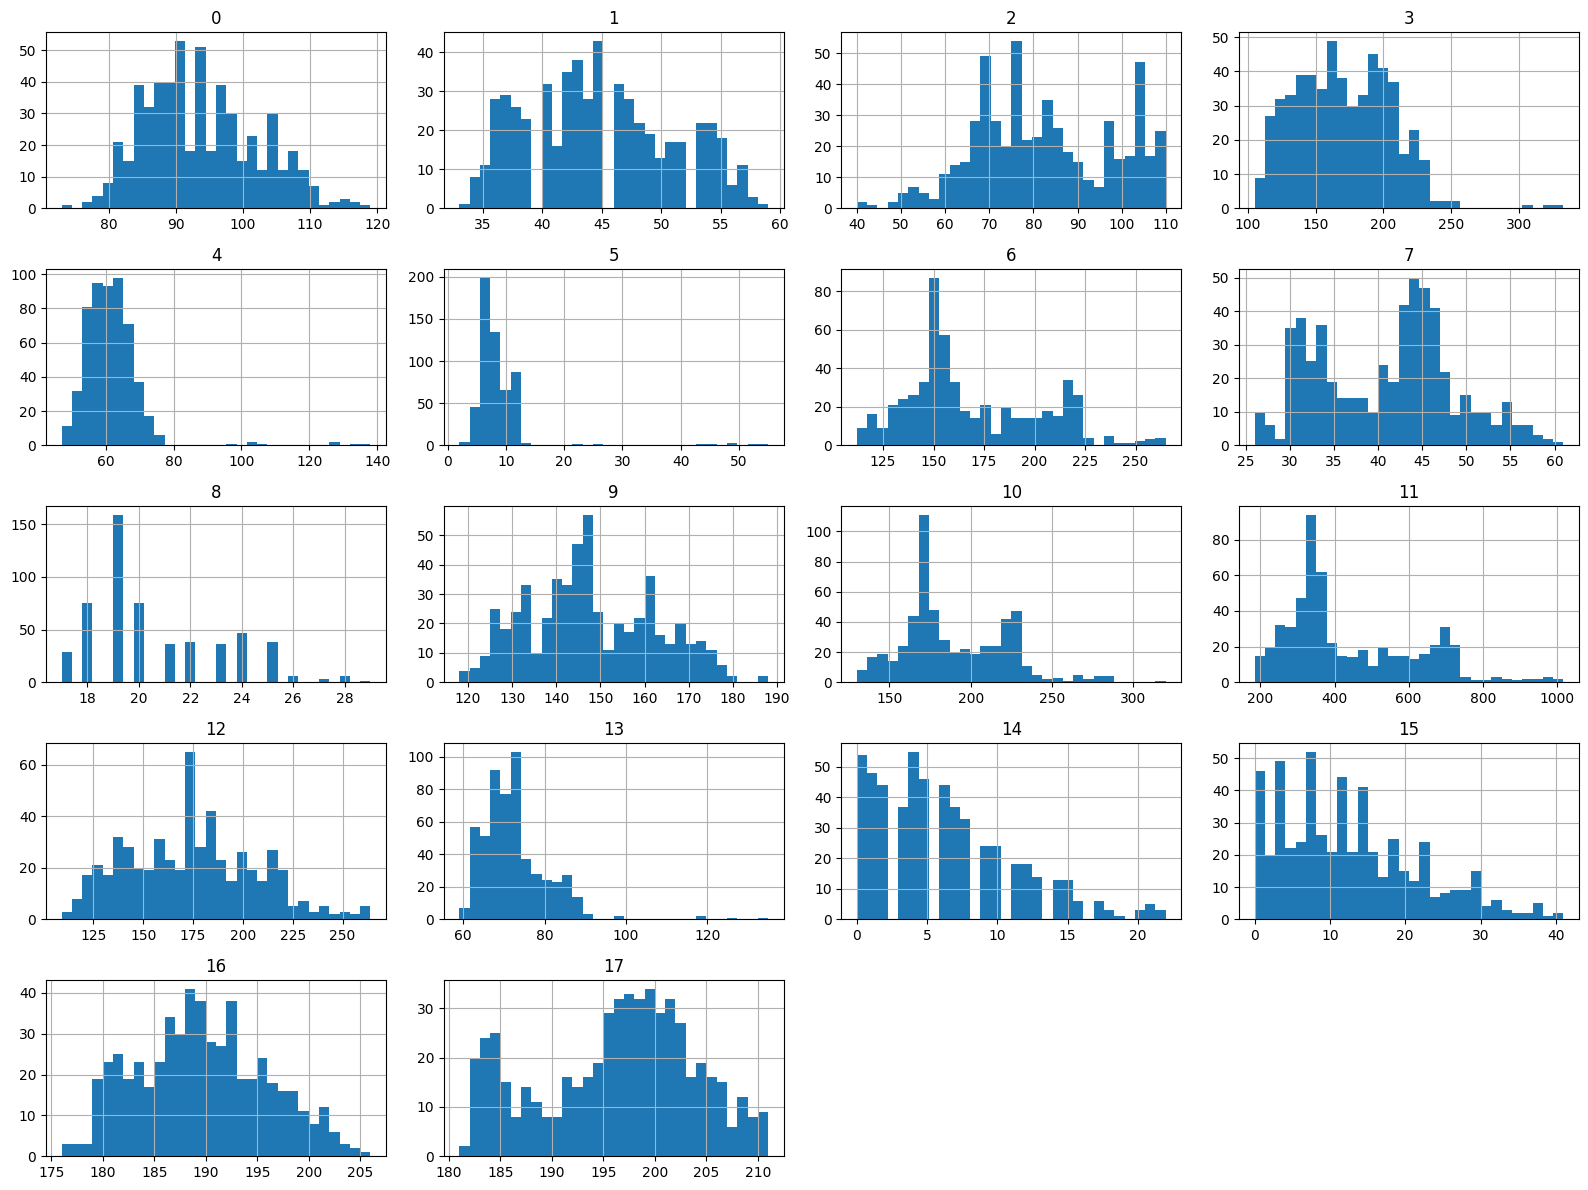

In [12]:
import matplotlib.pyplot as plt
pd.DataFrame(X_train_new).hist(
    bins=30,
    figsize=(16, 12)
)
plt.tight_layout()
plt.show()

#### 2.1. Basic logistic regression
* Find optimal hyperparameters for logistic regression with cross-validation on the `train` data (small grid/random search is enough, no need to find the *best* parameters).

* Estimate the model quality with `f1` and `accuracy` scores.
* Plot a ROC-curve for the trained model. For the multiclass case you might use `scikitplot` library (e.g. `scikitplot.metrics.plot_roc(test_labels, predicted_proba)`).

*Note: please, use the following hyperparameters for logistic regression: `multi_class='multinomial'`, `solver='saga'` `tol=1e-3` and ` max_iter=500`.*

In [13]:

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

# модель логрег (в этой версии уже без multi_class)
model = LogisticRegression(solver='saga',tol=1e-3, max_iter=500)

# пайплайн
pipeline = Pipeline([('scaler', StandardScaler()),('model', model)])

# список C
param_grid = {'model__C': [0.01, 0.1, 1, 10, 100, 300, 1000]}

# кросс-валидация
gs = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='f1_macro',
)

# поиск лучших параметров
gs.fit(X_train_new, y_train)

print("Лучшие параметры:", gs.best_params_)
print("Лучший f1_macro:", gs.best_score_)


Лучшие параметры: {'model__C': 100}
Лучший f1_macro: 0.787600506565496


In [14]:
from sklearn.metrics import accuracy_score, f1_score
# используем лучшую модель
best_model = gs.best_estimator_
y_pred = best_model.predict(X_test_new)

accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average='macro')

print(f"accuracy: {accuracy:.4f}")
print(f"f1: {f1:.4f}")

accuracy: 0.8081
f1: 0.8128


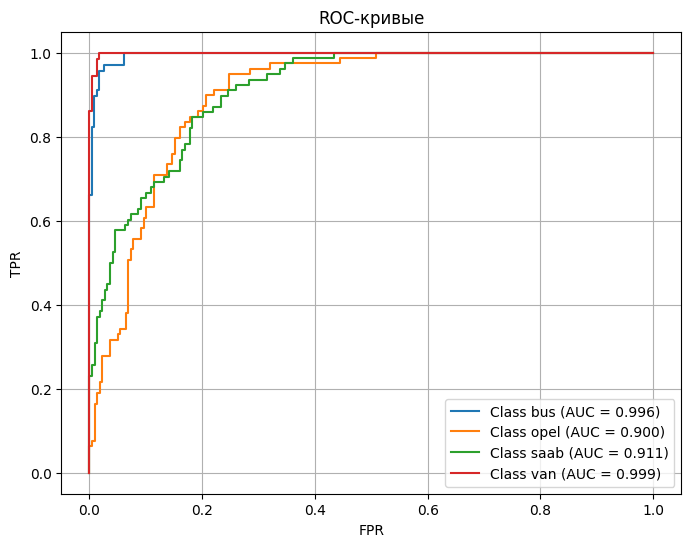

In [15]:
from sklearn.metrics import roc_curve, auc
# теперь находим вероятности
y_proba = best_model.predict_proba(X_test_new)

plt.figure(figsize=(8, 6))

# cтроим ROC-кривую для каждого класса
for i, class_label in enumerate(best_model.classes_):

    y_test_binary = (y_test == class_label).astype(int)
    y_score = y_proba[:, i]

    fpr, tpr, thresholds = roc_curve(y_test_binary, y_score)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f'Class {class_label} (AUC = {roc_auc:.3f})')

plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('ROC-кривые')
plt.legend()
plt.grid()
plt.show()


### Вывод

Для подбора параметра регуляризации в логистической регрессии использовался `GridSearchCV`. Наилучший результат получен при C = 100, среднее значение F1-macro на кросс-валидации составило 0.79.
На тестовой выборке получены следующие результаты:
- **Accuracy = 0.8081**
- **F1-macro = 0.8128**

По ROC-кривым видно, что модель лучше всего различает классы `van` и `bus`. Для классов `opel` и `saab` качество ниже.

Таким образом, логистическая регрессия показала достаточно хорошие результаты, однако качество классификации отдельных классов ещё можно улучшить.

In [ ]:
# You might use this command to install scikit-plot.
# Warning, if you a running locally, don't call pip from within jupyter, call it from terminal in the corresponding
# virtual environment instead

# ! pip install scikit-plot

#### 2.2. PCA: explained variance plot
* Apply the PCA to the train part of the data. Build the explaided variance plot.

In [16]:
from sklearn.decomposition import PCA

pca = PCA()
pca.fit(X_train_scaled)

print(pca.explained_variance_ratio_)

[5.15317192e-01 1.67490915e-01 1.16939500e-01 6.72624058e-02
 4.95141888e-02 2.92444226e-02 1.79714864e-02 1.16271346e-02
 8.76749032e-03 4.97493957e-03 3.54438340e-03 2.29256918e-03
 1.93619836e-03 1.17248238e-03 9.00473917e-04 6.73573866e-04
 3.49996355e-04 2.06479323e-05]


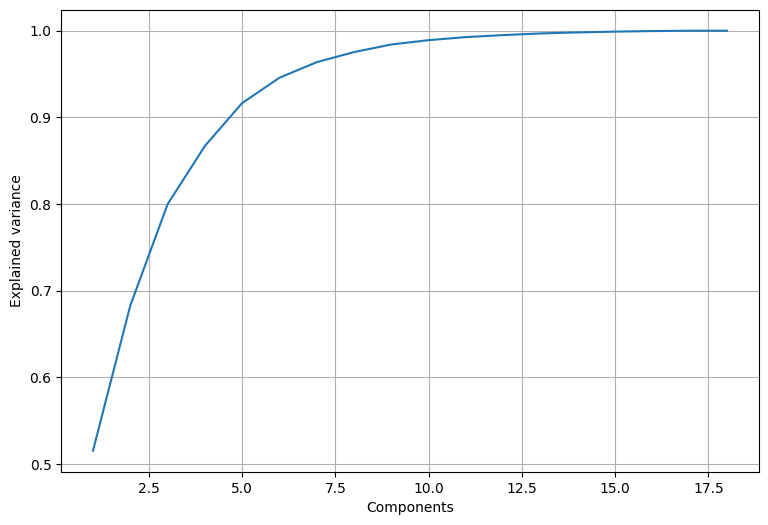

In [17]:
# посмотрим как копится объяснённая дисперсия
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

components = np.arange(1, len(explained_variance) + 1)

plt.figure(figsize=(9, 6))
plt.plot(components, cumulative_variance)

plt.xlabel('Сomponents')
plt.ylabel('Explained variance')
plt.grid()
plt.show()


#### 2.3. PCA trasformation
* Select the appropriate number of components. Briefly explain your choice. Should you normalize the data?

*Use `fit` and `transform` methods to transform the `train` and `test` parts.*

По графику выше видно, что первые 9 главных компонент объясняют примерно 97-98% общей дисперсии данных. Далее график выходит почти на плато. Поэтому выберем 9 главных компонент.

Перед применением PCA необходимо стандартизировать признаки, поскольку они имеют разные масштабы. Без стандартизации признаки с большей дисперсией из-за своего масштаба могут оказывать непропорционально большое влияние на главные компоненты

In [18]:
pca_9 = PCA(n_components=9)
pca_9.fit(X_train_scaled)

X_train_pca = pca_9.transform(X_train_scaled)
X_test_pca = pca_9.transform(X_test_scaled)

In [19]:
print(X_train_pca.shape)
print(X_test_pca.shape)

(549, 9)
(297, 9)


**Note: From this point `sklearn` [Pipeline](https://scikit-learn.org/stable/modules/compose.html) might be useful to perform transformations on the data. Refer to the [docs](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html) for more information.**

#### 2.4. Logistic regression on PCA-preprocessed data.
* Find optimal hyperparameters for logistic regression with cross-validation on the transformed by PCA `train` data.

* Estimate the model quality with `f1` and `accuracy` scores.
* Plot a ROC-curve for the trained model. For the multiclass case you might use `scikitplot` library (e.g. `scikitplot.metrics.plot_roc(test_labels, predicted_proba)`).

*Note: please, use the following hyperparameters for logistic regression: `multi_class='multinomial'`, `solver='saga'` and `tol=1e-3`*

In [20]:
# новый pipeline - учитываем там pca
pipeline_pca = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=9)),
    ('model', LogisticRegression(
        solver='saga',
        tol=1e-3,
        max_iter=500
    ))
])

param_grid = {
    'model__C': [0.01, 0.1, 1, 10, 100, 300, 1000]
}

gs_pca = GridSearchCV(
    estimator=pipeline_pca,
    param_grid=param_grid,
    cv=5,
    scoring='f1_macro'
)

gs_pca.fit(X_train_new, y_train)

best_model_pca = gs_pca.best_estimator_

y_pred_pca = best_model_pca.predict(X_test_new)

accuracy_pca = accuracy_score(y_test, y_pred_pca)
f1_pca = f1_score(y_test, y_pred_pca, average='macro')

print("Лучшие параметры:", gs_pca.best_params_)
print(f"f1-macro: {gs_pca.best_score_:.4f}")
print(f"accuracy для test: {accuracy_pca:.4f}")
print(f"f1-macro для test: {f1_pca:.4f}")


Лучшие параметры: {'model__C': 100}
f1-macro: 0.6850
accuracy для test: 0.7340
f1-macro для test: 0.7386


Качество модели ухудшилось. Попробуем посмотреть на бОльшем количестве компонент

In [21]:
param_grid_pca = {
    'pca__n_components': [9, 11, 13, 15, 17, 18],
    'model__C': [0.01, 0.1, 1, 10, 100]
}

gs_pca = GridSearchCV(
    pipeline_pca,
    param_grid_pca,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

gs_pca.fit(X_train_new, y_train)

print("Лучшие параметры:", gs_pca.best_params_)
print(f"f1-macro: {gs_pca.best_score_:.4f}")

Лучшие параметры: {'model__C': 100, 'pca__n_components': 17}
f1-macro: 0.7876


In [22]:
best_model_pca_2 = gs_pca.best_estimator_

y_pred_pca = best_model_pca_2.predict(X_test_new)

accuracy_pca = accuracy_score(y_test, y_pred_pca)
f1_pca = f1_score(y_test, y_pred_pca, average='macro')

print(f"Accuracy: {accuracy_pca:.4f}")
print(f"F1-macro: {f1_pca:.4f}")

Accuracy: 0.8182
F1-macro: 0.8224


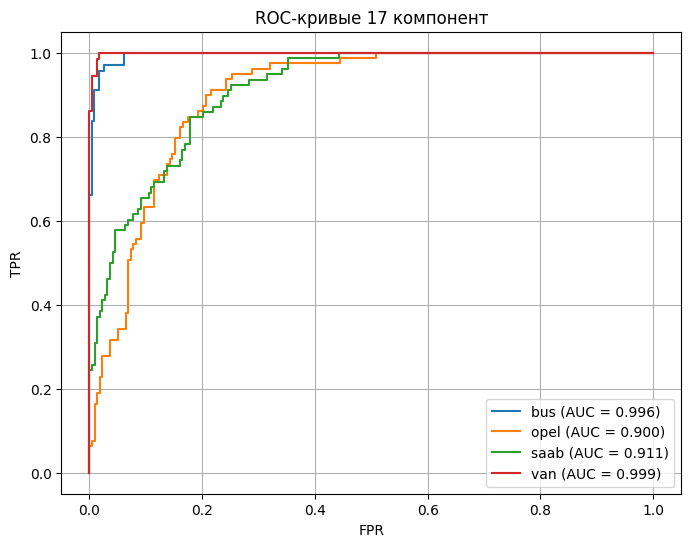

In [42]:
# вероятности классов
y_proba_pca = best_model_pca_2.predict_proba(X_test_new)

plt.figure(figsize=(8, 6))

# ROC-кривые
for i, class_label in enumerate(best_model_pca_2.classes_):

    y_test_binary = (y_test == class_label).astype(int)
    y_score = y_proba_pca[:, i]

    fpr, tpr, _ = roc_curve(y_test_binary, y_score)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr,label=f'{class_label} (AUC = {roc_auc:.3f})')


plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('ROC-кривые 17 компонент')
plt.legend()
plt.grid()

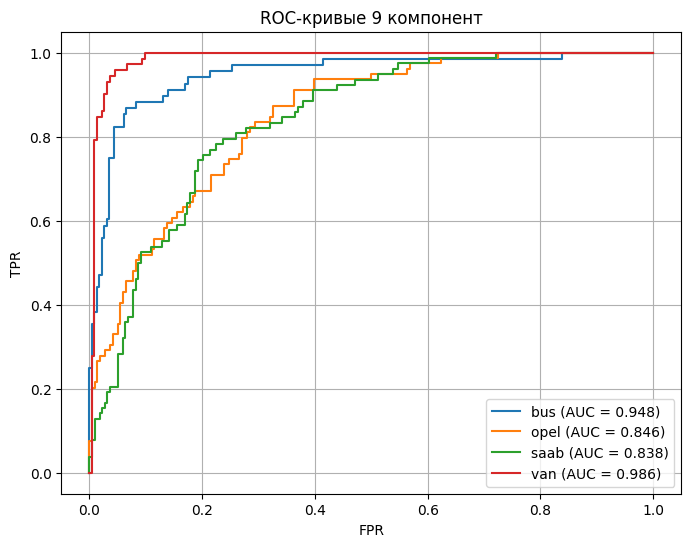

In [43]:
# вероятности классов
y_proba_pca = best_model_pca.predict_proba(X_test_new)

plt.figure(figsize=(8, 6))

# ROC-кривые
for i, class_label in enumerate(best_model_pca.classes_):

    y_test_binary = (y_test == class_label).astype(int)
    y_score = y_proba_pca[:, i]

    fpr, tpr, _ = roc_curve(y_test_binary, y_score)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr,label=f'{class_label} (AUC = {roc_auc:.3f})')


plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('ROC-кривые 9 компонент')
plt.legend()
plt.grid()

При использовании PCA с 9 главными компонентами качество логистической регрессии упало: F1 на тестовой выборке составил 0.74 vs 0.81 без PCA.

Несмотря на сохранение около 98% дисперсии, часть важной информации, вероятно, была потеряна.

Дополнительно с помощью GridSearchCV было подобрано количество главных компонент. Лучший результат на кросс-валидации получен при 17 компонентах и C = 100: F1 = 0.7876. На тестовой выборке F1 составил 0.8224, что немного выше результата модели без PCA.

Таким образом, PCA с заметно меньшим количеством компонентов (9) улучшения качества классификации не дал.

Сравнение AUC:

**bus**: 0.996 без PCA, 0.996	PCA 17, 0.948 PCA 9

**opel**: 0.900 без PCA, 0.900	PCA 17, 0.846 PCA 9

**saab**: 0.911 без PCA, 0.911	PCA 17, 0.838 PCA 9

**van**: 0.999 без PCA, 0.999	PCA 17, 0.986 PCA 9

* PCA (17): качество разделения классов практически не отличается от исходной логистической регрессии
* PCA (9): значения AUC снизились для всех четырёх классов
* Наиболее заметное снижение у saab: с 0.911 до 0.838

#### 2.5. Decision tree
* Now train a desicion tree on the same data. Find optimal tree depth (`max_depth`) using cross-validation.

* Measure the model quality using the same metrics you used above.

In [23]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=42)

param_grid_tree = {'max_depth': range(1, 21)}

gs_tree = GridSearchCV(
    estimator=tree,
    param_grid=param_grid_tree,
    cv=5,
    scoring='f1_macro'
)

gs_tree.fit(X_train_new, y_train)

best_tree = gs_tree.best_estimator_

y_pred_tree = best_tree.predict(X_test_new)

accuracy_tree = accuracy_score(y_test, y_pred_tree)
f1_tree = f1_score(y_test, y_pred_tree, average='macro')

print("Лучшая глубина:", gs_tree.best_params_)
print(f"F1-macro: {gs_tree.best_score_:.4f}")
print(f"Accuracy на test: {accuracy_tree:.4f}")
print(f"F1-macro на test: {f1_tree:.4f}")

Лучшая глубина: {'max_depth': 13}
F1-macro: 0.6834
Accuracy на test: 0.6902
F1-macro на test: 0.6955


Для дерева решений с помощью GridSearchCV была подобрана оптимальная глубина `max_depth = 13`. Значение F1 на кросс-валидации составило 0.6834, на тестовой выборке — 0.6955.

Дерево решений показало более низкое качество классификации по сравнению с логистической регрессией.

#### 2.6. Bagging.
Here starts the ensembling part.

First we will use the __Bagging__ approach. Build an ensemble of $N$ algorithms varying N from $N_{min}=2$ to $N_{max}=100$ (with step 5).

We will build two ensembles: of logistic regressions and of decision trees.

*Comment: each ensemble should be constructed from models of the same family, so logistic regressions should not be mixed up with decision trees.*


*Hint 1: To build a __Bagging__ ensebmle varying the ensemble size efficiently you might generate $N_{max}$ subsets of `train` data (of the same size as the original dataset) using bootstrap procedure once. Then you train a new instance of logistic regression/decision tree with optimal hyperparameters you estimated before on each subset (so you train it from scratch). Finally, to get an ensemble of $N$ models you average the $N$ out of $N_{max}$ models predictions.*

*Hint 2: sklearn might help you with this taks. Some appropriate function/class might be out there.*

* Plot `f1` and `accuracy` scores plots w.r.t. the size of the ensemble.

* Briefly analyse the plot. What is the optimal number of algorithms? Explain your answer.

* How do you think, are the hyperparameters for the decision trees you found in 2.5 optimal for trees used in ensemble?

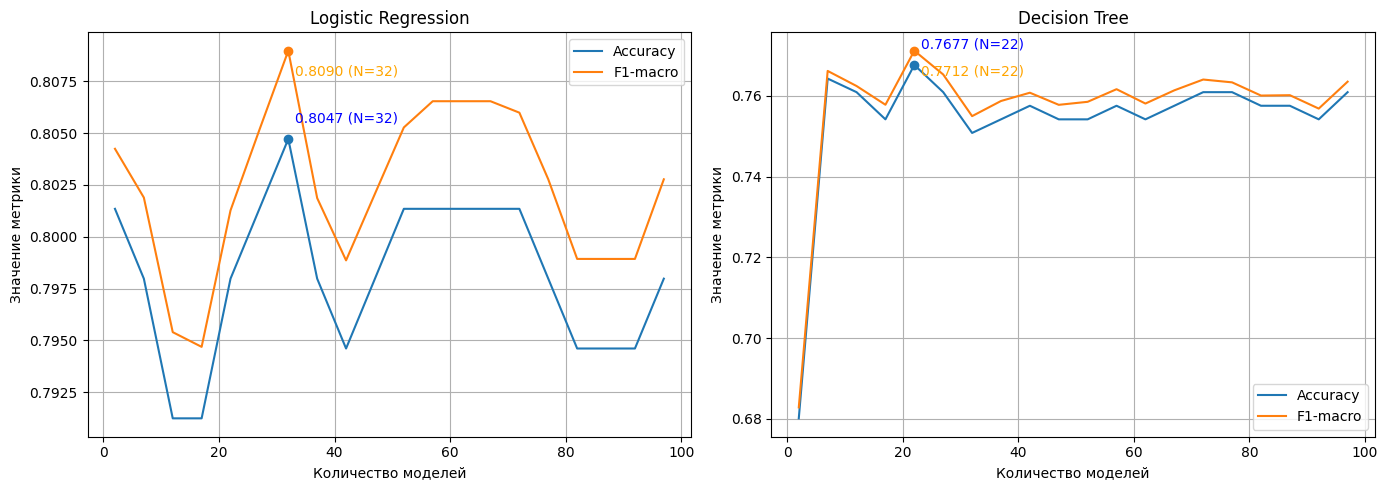

In [25]:
from sklearn.ensemble import BaggingClassifier
import matplotlib.pyplot as plt

# логрег
pipeline_logreg = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        C=100,
        solver='saga',
        tol=1e-3,
        max_iter=500,
        random_state=42
    ))
])

# дерево решений
tree = DecisionTreeClassifier(
    max_depth=13,
    random_state=42
)

# Количество моделей
n_models = list(range(2, 101, 5))

results = {}

for name, estimator in [('Logistic Regression', pipeline_logreg), ('Decision Tree', tree)]:
    accuracy_scores = []
    f1_scores = []

    for n in n_models:
        bagging = BaggingClassifier(
            estimator=estimator,
            n_estimators=n,
            random_state=42)

        bagging.fit(X_train_new, y_train)
        y_pred = bagging.predict(X_test_new)

        accuracy_scores.append(accuracy_score(y_test, y_pred))
        f1_scores.append(f1_score(y_test, y_pred, average='macro'))

    results[name] = {
        'accuracy': accuracy_scores,
        'f1': f1_scores
    }

plt.figure(figsize=(14, 5))

for i, (name, scores) in enumerate(results.items(), 1):
    plt.subplot(1, 2, i)

    plt.plot(n_models, scores['accuracy'], label='Accuracy')
    plt.plot(n_models, scores['f1'], label='F1-macro')

    max_acc_idx = np.argmax(scores['accuracy'])
    max_acc = scores['accuracy'][max_acc_idx]
    max_acc_n = n_models[max_acc_idx]

    plt.scatter(max_acc_n, max_acc, zorder=5)
    plt.annotate(
        f'{max_acc:.4f} (N={max_acc_n})',
        (max_acc_n, max_acc),
        xytext=(5, 12),
        textcoords='offset points',
        color='blue'
    )

    max_f1_idx = np.argmax(scores['f1'])
    max_f1 = scores['f1'][max_f1_idx]
    max_f1_n = n_models[max_f1_idx]

    plt.scatter(max_f1_n, max_f1, zorder=5)
    plt.annotate(
        f'{max_f1:.4f} (N={max_f1_n})',
        (max_f1_n, max_f1),
        xytext=(5, -18),
        textcoords='offset points',
        color='orange'
    )

    plt.xlabel('Количество моделей')
    plt.ylabel('Значение метрики')
    plt.title(name)
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.show()

При увеличении количества моделей в ансамбле качество меняется нелинейно и немонотонно.

Для логистической регрессии bagging не дал улучшений: максимальный F1 на тестовой выборке составил 0.8090 против 0.8128 у одиночной модели. Оптимальное количество моделей на тесте(наибольший F1) = 32

Для деревьев улучшение заметное: максимальный F1 на тестовой выборке составил  0.7712 против 0.6955 у одиночного дерева. Оптимальное количество моделей на тесте (наибольший F1) = 22. Так происходит, тк деревья более чувствительны к изменениям обучающей выборки, а бэггинг позволяет снизить разброс предсказаний.

**Будет ли max_depth=13 оптимальной глубиной дерева внутри бэггинга?**

Не обязательно. Бэггинг снижает разброс предсказаний, что может хорошо сыграть на более глубоких деревьях, которые по одиночке более склонны к переобучению


#### 2.7. Random Forest
Now we will work with the Random Forest (its `sklearn` implementation).

* * Plot `f1` and `accuracy` scores plots w.r.t. the number of trees in Random Forest.

* What is the optimal number of trees you've got? Is it different from the optimal number of logistic regressions/decision trees in 2.6? Explain the results briefly.

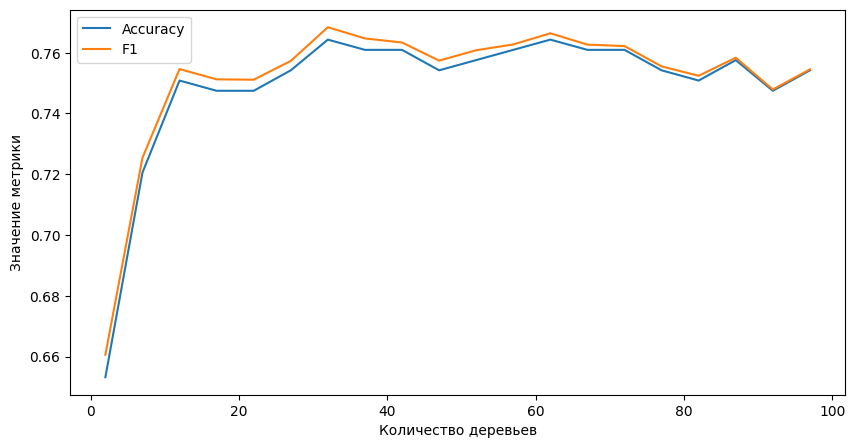

Количество деревьев: 32
Максимальный F1: 0.7684
Accuracy: 0.7643


In [26]:
from sklearn.ensemble import RandomForestClassifier

# количество деревьев
n_trees = list(range(2, 101, 5))

accuracy_rf = []
f1_rf = []

# обучение случайного леса
for n in n_trees:
    forest = RandomForestClassifier(
        n_estimators=n,
        random_state=42
    )

    forest.fit(X_train_new, y_train)
    y_pred_rf = forest.predict(X_test_new)

    accuracy_rf.append(accuracy_score(y_test, y_pred_rf))
    f1_rf.append(f1_score(y_test, y_pred_rf, average='macro'))

plt.figure(figsize=(10, 5))

plt.plot(n_trees, accuracy_rf, label='Accuracy')
plt.plot(n_trees, f1_rf, label='F1')

plt.xlabel('Количество деревьев')
plt.ylabel('Значение метрики')
plt.legend()
plt.show()

# Лучший результат по F1
best_f1 = f1_rf.index(max(f1_rf))

print("Количество деревьев:", n_trees[best_f1])
print(f"Максимальный F1: {f1_rf[best_f1]:.4f}")
print(f"Accuracy: {accuracy_rf[best_f1]:.4f}")

In [27]:
depths = [tree.get_depth() for tree in forest.estimators_]

print("Минимальная глубина:", min(depths))
print("Максимальная глубина:", max(depths))
print("Средняя глубина:", sum(depths) / len(depths))

Минимальная глубина: 11
Максимальная глубина: 21
Средняя глубина: 14.917525773195877


При увеличении количества деревьев в Random Forest качество сначала быстро растёт, но потом выходит на плато

Максимальный F1 на тестовой выборке составил 0.7684 при 32 деревьях, accuracy — 0.7643. Для бэггинга деревьев максимум наблюдался при 22 моделях, а для бэггинга логистических регрессий — при 32.

Random Forest показал F1-macro = 0.7684, что практически совпадает с результатом бэггинга деревьев (0.7712).

При этом в бэггинге использовались деревья с max_depth=13, а в Random Forest глубина не ограничивалась (там в среднем 15)

Пока что логистическая регрессия сохраняет преимущество по качеству классификации

#### 2.8. Learning curve
Your goal is to estimate, how does the model behaviour change with the increase of the `train` dataset size.

* Split the training data into 10 equal (almost) parts. Then train the models from above (Logistic regression, Desicion Tree, Random Forest) with optimal hyperparameters you have selected on 1 part, 2 parts (combined, so the train size in increased by 2 times), 3 parts and so on.

* Build a plot of `accuracy` and `f1` scores on `test` part, varying the `train` dataset size (so the axes will be score - dataset size.

* Analyse the final plot. Can you make any conlusions using it?

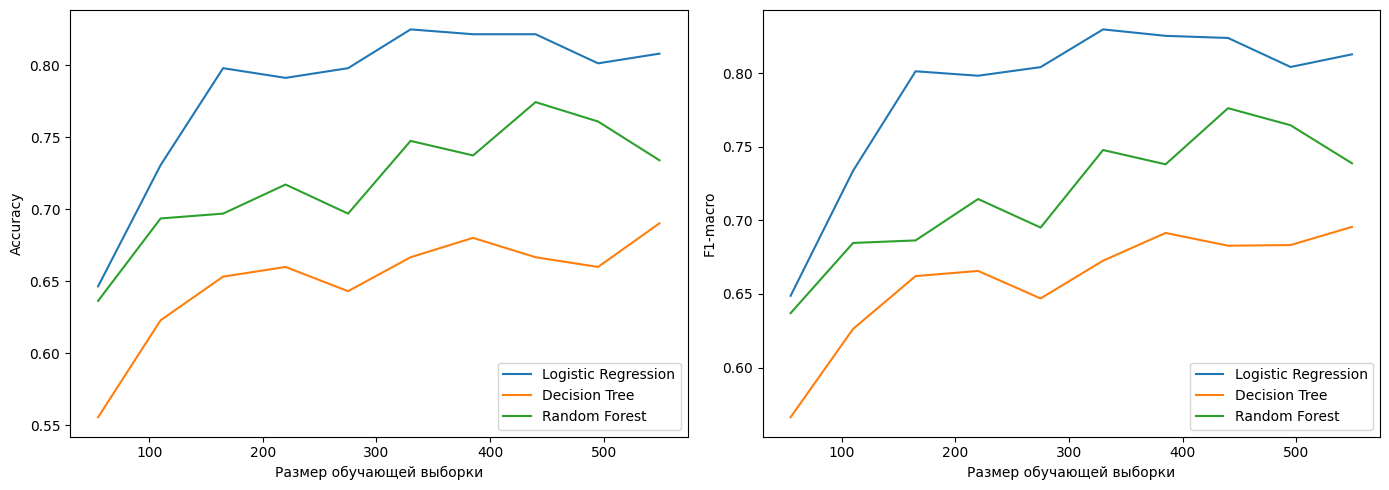

In [30]:
np.random.seed(42)

indices = np.random.permutation(len(X_train_new))
parts = np.array_split(indices, 10)

models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(
            C=100,
            solver='saga',
            tol=1e-3,
            max_iter=2000,
            random_state=42
        ))
    ]),
    'Decision Tree': DecisionTreeClassifier(
        max_depth=13,
        random_state=42
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=32,
        random_state=42
    )
}

# сюда будем записываь результаты
sizes = []
results = {}

for name in models:results[name] = {'accuracy': [], 'f1': []}


for n in range(1, 11):
  new_train_parts = parts[:n]
  train_arr = np.concatenate(new_train_parts)

  X_sub = X_train_new[train_arr]
  y_sub = y_train[train_arr]

  sizes.append(len(X_sub))

  # прогоняем каждую модель
  for name, model in models.items():

      model.fit(X_sub, y_sub)
      y_pred = model.predict(X_test_new)

      accuracy = accuracy_score(y_test, y_pred)
      f1 = f1_score(y_test, y_pred, average='macro')

      results[name]['accuracy'].append(accuracy)
      results[name]['f1'].append(f1)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
for name, scores in results.items():
    plt.plot(sizes, scores['accuracy'], label=name)

plt.xlabel('Размер обучающей выборки')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
for name, scores in results.items():
    plt.plot(sizes, scores['f1'], label=name)

plt.xlabel('Размер обучающей выборки')
plt.ylabel('F1-macro')
plt.legend()

plt.tight_layout()
plt.show()

При увеличении размера обучающей выборки качество всех трёх моделей в целом улучшается, особенно на начальных этапах

Лучшее качество показала логистическая регрессия: F1 достигает примерно 0.83 при 330–350 объектах, после чего выходит на плато с небольшими колебаниями

Random Forest также демонстрирует рост качества с увеличением количества данных, достигая F1 около 0.78. Одиночное дерево решений показывает наиболее низкие результаты — максимальный F1 составляет около 0.70.

Таким образом, увеличение объёма обучающих данных положительно влияет на качество классификации, но после определённого размера выборки улучшения становятся менее выраженными.

#### 2.9. Boosting
Your goal is to build a boosting ensemble using xgboost, CatBoost or lightgbm package.
Please, do not use the sklearn API for these models.

Find optimal number of decision trees in the boosting ensembe using grid search or other methods.
Please, explain your answer.

In [31]:
# разделяем нашу обучающую выборку на еще 2 - для обучения и для валидации+подбора кол-ва деревьев
X_train_boost, X_val, y_train_boost, y_val = train_test_split(
    X_train_new,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

In [33]:
# необходимо строковые классы преобразовать в числовые
from sklearn.preprocessing import LabelEncoder
import xgboost as xgb

encoder = LabelEncoder()

y_train_encoded = encoder.fit_transform(y_train_boost)
y_val_encoded = encoder.transform(y_val)

print(encoder.classes_)
print(y_train_encoded)

['bus' 'opel' 'saab' 'van']
[1 0 1 0 3 1 3 1 2 0 2 3 2 2 2 0 0 3 2 0 2 1 1 2 1 2 3 2 3 1 0 3 0 2 3 0 2
 1 2 1 0 3 2 2 2 2 3 3 1 1 0 2 0 1 3 3 3 0 0 0 3 3 0 1 2 2 1 1 0 2 0 1 3 1
 1 1 3 3 0 1 3 3 0 2 0 2 1 3 2 2 2 1 0 3 3 2 1 2 0 0 0 1 1 0 2 2 3 1 0 2 1
 3 0 0 2 0 2 2 2 0 1 1 1 1 2 2 1 3 0 1 1 1 0 2 0 0 0 1 1 0 0 0 2 3 3 2 1 1
 2 3 2 0 1 2 3 0 2 2 2 0 2 0 1 0 3 3 0 1 3 2 2 3 2 2 0 0 0 3 2 2 2 3 3 0 3
 3 1 1 3 3 1 0 2 0 3 2 1 3 2 1 3 0 0 2 2 1 0 2 1 0 1 0 0 1 2 1 3 2 0 2 3 2
 2 2 2 0 1 0 0 3 1 1 3 0 0 0 0 0 2 0 1 2 0 1 3 0 2 0 2 0 0 2 0 2 3 3 3 0 3
 3 0 3 0 0 2 3 0 2 3 3 2 3 0 0 3 2 3 0 1 2 0 3 0 0 2 2 1 1 3 1 2 0 3 0 1 3
 3 0 2 3 0 1 2 1 0 3 2 0 2 1 0 2 3 0 0 1 2 1 2 3 1 1 0 1 2 3 2 1 3 0 3 1 0
 2 1 1 0 2 1 0 3 1 2 3 1 1 3 3 3 1 0 1 1 2 2 0 2 1 2 3 2 1 3 2 3 1 3 1 0 0
 1 3 2 1 1 1 1 0 2 2 0 0 3 2 1 2 2 1 1 1 1 1 3 1 0 1 0 0 0 3 1 0 3 0 3 0 0
 3 1 3 3 0 3 1 1 2 2 0 3 2 3 0 1 0 1 3 3 3 3 0 0 3 2 2 3 3 1 2 0]


In [34]:
# готовим данные в нужном формате
dtrain = xgb.DMatrix(X_train_boost, label=y_train_encoded)
dval = xgb.DMatrix(X_val, label=y_val_encoded)

Лучшее количество раундов: 25
F1-macro: 0.7207
Accuracy: 0.7273


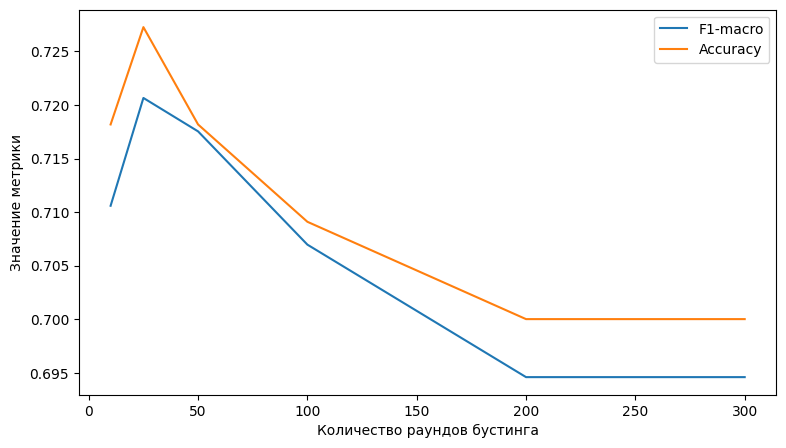

In [37]:
# количество раундов
n_rounds = [10, 25, 50, 100, 200, 300]

# параметры для модели
params = {
    'objective': 'multi:softprob',
    'num_class': 4,
    'eval_metric': 'mlogloss'
}

f1_scores = []
accuracy_scores = []

for n in n_rounds:
    model = xgb.train(
        params=params,
        dtrain=dtrain,
        num_boost_round=n
    )

    y_proba = model.predict(dval)
    y_pred = np.argmax(y_proba, axis=1)

    f1_scores.append(f1_score(y_val_encoded, y_pred, average='macro'))
    accuracy_scores.append(accuracy_score(y_val_encoded, y_pred))

# находим лучший результат по F1
best_idx = np.argmax(f1_scores)
best_n = n_rounds[best_idx]

print("Лучшее количество раундов:", best_n)
print(f"F1-macro: {f1_scores[best_idx]:.4f}")
print(f"Accuracy: {accuracy_scores[best_idx]:.4f}")

# график
plt.figure(figsize=(9, 5))

plt.plot(n_rounds, f1_scores, label='F1-macro')
plt.plot(n_rounds, accuracy_scores, label='Accuracy')

plt.xlabel('Количество раундов бустинга')
plt.ylabel('Значение метрики')
plt.legend()
plt.show()

Лучшее количество раундов: 25
F1-macro: 0.7207
Accuracy: 0.7273


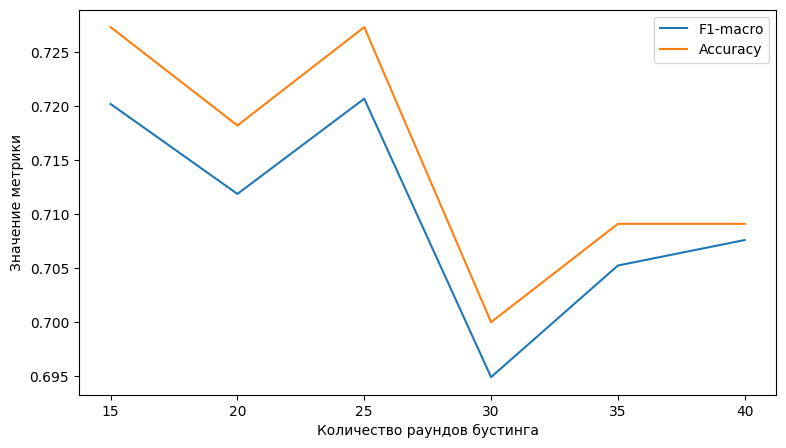

In [38]:
# посмотрим подробнее вокруг 25

n_rounds = range(15, 45, 5)
# параметры для модели
params = {
    'objective': 'multi:softprob',
    'num_class': 4,
    'eval_metric': 'mlogloss'
}

f1_scores = []
accuracy_scores = []

for n in n_rounds:
    model = xgb.train(
        params=params,
        dtrain=dtrain,
        num_boost_round=n
    )

    y_proba = model.predict(dval)
    y_pred = np.argmax(y_proba, axis=1)

    f1_scores.append(f1_score(y_val_encoded, y_pred, average='macro'))
    accuracy_scores.append(accuracy_score(y_val_encoded, y_pred))

# находим лучший результат по F1
best_idx = np.argmax(f1_scores)
best_n = n_rounds[best_idx]

print("Лучшее количество раундов:", best_n)
print(f"F1-macro: {f1_scores[best_idx]:.4f}")
print(f"Accuracy: {accuracy_scores[best_idx]:.4f}")

# график
plt.figure(figsize=(9, 5))

plt.plot(n_rounds, f1_scores, label='F1-macro')
plt.plot(n_rounds, accuracy_scores, label='Accuracy')

plt.xlabel('Количество раундов бустинга')
plt.ylabel('Значение метрики')
plt.legend()
plt.show()

Для подбора количества раундов бустинга XGBoost использовался Grid Search с оценкой F1 на валидационной выборке.

Сначала были проверены значения от 10 до 300 раундов, затем выполнен более подробный поиск в диапазоне от 15 до 40 с шагом 5

Наилучший результат получен при 25 раундах: F1 = 0.7207, Accuracy = 0.7273.

При дальнейшем увеличении количества раундов качество на валидационной выборке в целом снижалось. Это может происходит из-за переобучения модели


In [39]:
# финальная модель на всей обучющей выборке

dtrain_full = xgb.DMatrix(X_train_new, label=encoder.transform(y_train))
dtest = xgb.DMatrix(X_test_new)

final_model = xgb.train(
    params=params,
    dtrain=dtrain_full,
    num_boost_round=best_n
)

y_proba = final_model.predict(dtest)

y_pred_encoded = np.argmax(y_proba, axis=1)
y_pred = encoder.inverse_transform(y_pred_encoded)

accuracy_xgb = accuracy_score(y_test, y_pred)
f1_xgb = f1_score(y_test, y_pred, average='macro')

print(f"Количество раундов: {best_n}")
print(f"Accuracy: {accuracy_xgb:.4f}")
print(f"F1-macro: {f1_xgb:.4f}")

Количество раундов: 25
Accuracy: 0.7643
F1-macro: 0.7693


На тестовых данных Accuracy составила 0.7643, F1-macro — 0.7693. XGBoost уступает логистической регрессии, но превосходит одиночное дерево решений

